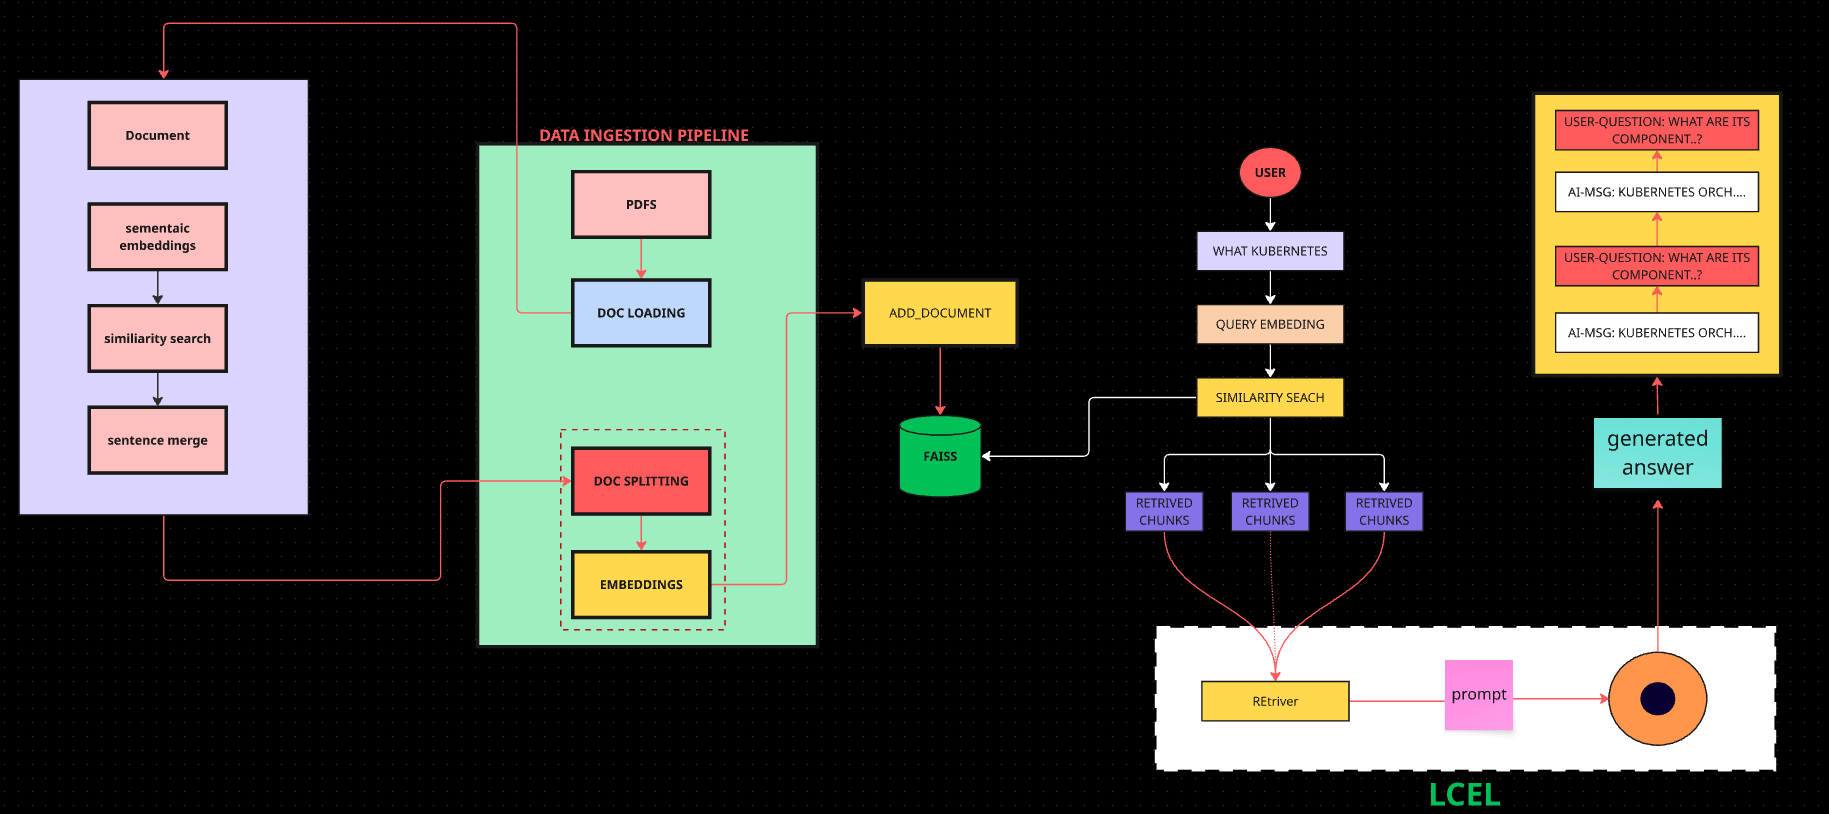

#  Advanced Semantic Chunking and RAG

In [1]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from langchain_core.documents import Document


text = """ 
LangChain is a framework for building applications with LLMs.
LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
You can create chains, agents, memory, and retrievers.
The Eiffel Tower is located in Paris.
France is a popular tourist destination.
"""

print(text)

 
LangChain is a framework for building applications with LLMs.
LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
You can create chains, agents, memory, and retrievers.
The Eiffel Tower is located in Paris.
France is a popular tourist destination.



In [ ]:
# STAGE:1 Document segmentation
sentences = []

for line in text.splitlines():
    line = line.strip()

    if line:
        sentences.append(line)



for i,sentence in enumerate(sentences):
    print(f"Sentence {i+1} and line:  {sentence}")


len(sentences)

Sentence 1 and line:  LangChain is a framework for building applications with LLMs.
Sentence 2 and line:  LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
Sentence 3 and line:  You can create chains, agents, memory, and retrievers.
Sentence 4 and line:  The Eiffel Tower is located in Paris.
Sentence 5 and line:  France is a popular tourist destination.


5

In [10]:
# STAGE2 SENTENCE EMBEDING
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sentence_emmbeddings = sentence_model.encode(
    sentences,
    normalize_embeddings=True
)

print("No of sentence:", len(sentences))
print(f"Embeding shape : {sentence_emmbeddings.shape}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8144.89it/s]


No of sentence: 5
Embeding shape : (5, 384)


In [11]:
# STAGE3 SEMANTIC SIMILIARITY SEARCH

threshold = 0.5

chunks = []
current_chunk = [sentences[0]]


for i in range(1,len(sentences)):
    similarity =  cosine_similarity(
        [sentence_emmbeddings[i-1]],
        [sentence_emmbeddings[i]]
    )[0][0]

    print(f"similarity between sentence {i} and {i+1} : {similarity:.3f}")

    if similarity >= threshold:
        current_chunk.append(sentences[i])
    else:
        chunks.append(" ".join(current_chunk))
        current_chunk = [sentences[i]]

# add final chunk

if current_chunk:
    chunks.append(" ".join(current_chunk))

for i, chunk in enumerate(chunks, start=1):
    print(f"\\nChunk {i}:\\n{chunk}")

similarity between sentence 1 and 2 : 0.826
similarity between sentence 2 and 3 : 0.456
similarity between sentence 3 and 4 : 0.022
similarity between sentence 4 and 5 : 0.378
\nChunk 1:\nLangChain is a framework for building applications with LLMs. LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
\nChunk 2:\nYou can create chains, agents, memory, and retrievers.
\nChunk 3:\nThe Eiffel Tower is located in Paris.
\nChunk 4:\nFrance is a popular tourist destination.


## Reusable semantic chunker class

This class supports both plain-text splitting and LangChain `Document` objects. The metadata from each source document is copied to each generated chunk.

In [14]:
class ThreasholdSemanticChunker:
    def __init__(self, model = "all-MiniLM-L6-v2",threshold=0.5 ):
        self.model = SentenceTransformer(model)
        self.threshold = threshold


    def split(self,text:str) -> list[str]:
        sentences = [line.strip() for line in text.splitlines() if line.strip()]

        if not sentences:
            return []

        embeddings = self.model.encode(
            sentences,
            normalize_embeddings=True
        )
        
        chunks = []
        current_chunk = [sentences[0]]

        for i in range(1, len(sentences)):
            similarity = cosine_similarity(
                [embeddings[i - 1]],
                [embeddings[i]]
            )[0][0]

            if similarity >= self.threshold:
                current_chunk.append(sentences[i])
            else:
                chunks.append(" ".join(current_chunk))
                current_chunk = [sentences[i]]

        if current_chunk:
            chunks.append(" ".join(current_chunk))

        return chunks

    def split_documents(self, documents: list[Document]) -> list[Document]:
        chunk_documents = []

        for document in documents:
            for chunk_text in self.split(document.page_content):
                chunk_documents.append(
                    Document(
                        page_content=chunk_text,
                        metadata=document.metadata.copy()
                    )
                )

        return chunk_documents



In [16]:
chunker = ThreasholdSemanticChunker(threshold=0.6)
chunker.split(text)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 20212.09it/s]


['LangChain is a framework for building applications with LLMs. LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.',
 'You can create chains, agents, memory, and retrievers.',
 'The Eiffel Tower is located in Paris.',
 'France is a popular tourist destination.']

In [17]:
from importlib import metadata


text = """ 
LangChain is a framework for building applications with LLMs.
LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
You can create chains, agents, memory, and retrievers.
The Eiffel Tower is located in Paris.
France is a popular tourist destination.
"""

documents = [
    Document(
        page_content=text,
        metadata = {"source": "langchain_intro.txt", "topic": "demo"}
    )
]

In [18]:
chunker = ThreasholdSemanticChunker(threshold=0.6)

chunk_documents = chunker.split_documents(documents)

for i,document in enumerate(chunk_documents,start=1):
    print(f"\\nChunk {i}")
    print("Text:", document.page_content)
    print("Metadata:", document.metadata)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7104.43it/s]


\nChunk 1
Text: LangChain is a framework for building applications with LLMs. LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}
\nChunk 2
Text: You can create chains, agents, memory, and retrievers.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}
\nChunk 3
Text: The Eiffel Tower is located in Paris.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}
\nChunk 4
Text: France is a popular tourist destination.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}


## 6. Configure API keys

In [26]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)


os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

required_keys = ["OPENAI_API_KEY","GROQ_API_KEY"]
missing_keys = [ key for key in required_keys if not os.getenv(key) ]

if missing_keys:
    print("Set these environment variables before running the RAG cells:", ", ".join(missing_keys))
else:
    print("API key environment variables are available.")

API key environment variables are available.


## 7. Create embeddings and a FAISS vector store

This example uses OpenAI embeddings for vector search. The semantic chunking model above is a separate local Sentence Transformers model.

In [27]:
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS

embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = FAISS.from_documents(
    chunk_documents,
    embedding_model
)

retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

print("FAISS vector store created.")

FAISS vector store created.


# Test retrieval before creating the RAG chain

Inspecting retrieved chunks helps debug chunking and retrieval separately from answer generation.

In [28]:
question = "What is LangChain used for?"

retrieved_documents = retriever.invoke(question)

for i, document in enumerate(retrieved_documents, start=1):
    print(f"\\nRetrieved document {i}:")
    print(document.page_content)
    print("Metadata:", document.metadata)

\nRetrieved document 1:
LangChain is a framework for building applications with LLMs. LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}
\nRetrieved document 2:
You can create chains, agents, memory, and retrievers.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}
\nRetrieved document 3:
The Eiffel Tower is located in Paris.
Metadata: {'source': 'langchain_intro.txt', 'topic': 'demo'}


In [23]:
def retrieve_context(inputs: dict) -> str:
    question = inputs["question"]
    documents = retriever.invoke(question)

    context = "\\n\\n".join(
        document.page_content
        for document in documents
    )

    return context


def get_question(inputs: dict) -> str:
    return inputs["question"]


# Test the functions independently
sample_inputs = {"question": "What is LangChain used for?"}

print("Question:", get_question(sample_inputs))
print("\\nRetrieved context:\\n", retrieve_context(sample_inputs))

Question: What is LangChain used for?
\nRetrieved context:\n LangChain is a framework for building applications with LLMs. LangChain provides modular abstractions to combine LLMs with tools like OpenAI and Pinecone.\n\nYou can create chains, agents, memory, and retrievers.\n\nThe Eiffel Tower is located in Paris.


In [31]:
from langchain_core.runnables import RunnableMap
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain.chat_models import init_chat_model

prompt = PromptTemplate.from_template(
    """Answer the question using only the context below.
If the answer is not present in the context, say you do not have enough information.

Context:
{context}

Question:
{question}

Answer:"""
)

llm = init_chat_model(
    model="groq:qwen/qwen3.8-27b",
    temperature=0
)

rag_chain = (
    RunnableMap({
        "context": retrieve_context,
        "question": get_question,
    })
    | prompt
    | llm
    | StrOutputParser()
)

print("RAG chain created.")

RAG chain created.


In [32]:
query = {"question": "What is LangChain used for?"}

answer = rag_chain.invoke(query)
print(answer)

LangChain is a framework for building applications with LLMs.
